In [10]:
import sys
sys.executable

'c:\\Users\\justin\\Desktop\\Millerton\\millerton_reservoir\\.venv\\Scripts\\python.exe'

In [11]:
# %matplotlib ipympl

import pandas as pd

import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import matplotlib.ticker as ticker

from pathlib import Path

from pyqualw2.utils import jday_to_date
from pyqualw2.config import Config
from pyqualw2.config.inputs import FlowInput
from pyqualw2.model_runner import ModelRunner
from pyqualw2.outputs import QWO, QWOLayers, MultiRunResult, RunResult

In [12]:


data_path = Path("./model/")
inputs = data_path / "inputs"
historic = data_path / "historic_data"

output_dir = Path("analysis_runs/CalSim_1210_Baseline")


temp = historic / "temp_data" / "1977_2022_temp.csv"


config_1210_baseline = Config.from_files(
    name="1210_baseline_S9",
    con=data_path / "w2_con.csv",
    bathymetry=inputs / "mbth_wb1.csv",
    profile=inputs / "mvpr1.npt",
    met_data=historic / "met_data" / "1977_to_2024_CEQUAL_met_inputs.csv",
    shade=inputs / "mshade.npt",
    temperature_tributaries=[inputs / "mtdt_br1.npt"],
    temp_data=[temp, temp, temp, temp],
    flow_data= historic / "flow_data" / "1210_S9_flow.csv",
    wind_sheltering=inputs / "mwsc.npt"
)

C:\Users\justin\Desktop\Millerton\pyqualw2\pyqualw2\config\inputs.py:976: DtypeWarning: Columns (0: Unnamed: 8) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(filename)


In [ ]:
#timedata can receive any ISO 8609-formatted datetime string
config_1210_baseline.con.timedata = ( '1977-10-01','2021-10-02', 1921)
config_1210_baseline.bathymetry.segment_data["ELWS [m]"] = 144.32

In [14]:
%%time

ModelRunner(config_1210_baseline, output_dir=output_dir, wait_time=20).run(overwrite=True)

CPU times: total: 6.03 s
Wall time: 53min 3s


In [4]:
flow_para_list = [historic / "flow_data" / "1210_FKC100_Flow.csv",
historic / "flow_data" / "1210_FKC300_Flow.csv",
historic / "flow_data" / "1210_FKC500_Flow.csv",
historic / "flow_data" / "1210_MC100_Flow.csv",
historic / "flow_data" / "1210_MC300_Flow.csv",
historic / "flow_data" / "1210_MC500_Flow.csv"
]    
configs_1210_baseline = config_1210_baseline.parameterize({"flow_data":flow_para_list})


In [30]:
ModelRunner(configs_1210_baseline, output_dir=output_dir, wait_time=10).run(overwrite=True)

C:\Users\justin\AppData\Local\Temp\ipykernel_97044\1911019054.py:5: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


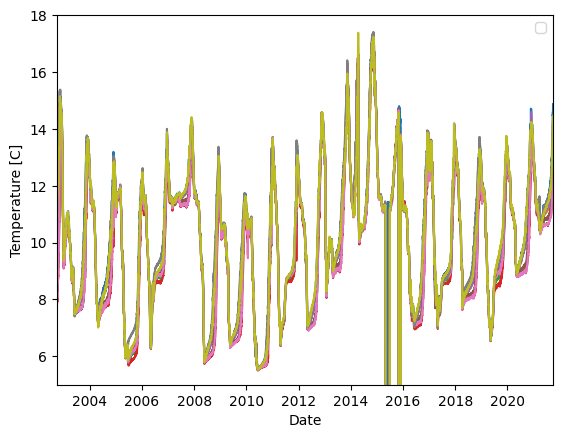

,Tavg [C],Tmin [C],Tmax [C],Days above threshold
1200_Baseline,9.353050,-99.0,17.40,508.0
1210_Baseline_1210_FKC100_Flow,8.759735,-99.0,17.34,354.0
1210_Baseline_1210_FKC300_Flow,8.428257,-99.0,17.31,214.0
1210_Baseline_1210_FKC500_Flow,8.312684,-99.0,17.20,196.0
1210_Baseline_1210_MC100_Flow,8.766596,-99.0,17.39,370.0
1210_Baseline_1210_MC300_Flow,8.487355,-99.0,17.27,221.0
1210_Baseline_1210_MC500_Flow,8.400431,-99.0,17.23,212.0
1210_baseline_S11,8.995642,-99.0,17.39,548.0
1210_baseline_S9,8.890480,-99.0,17.38,356.0


In [15]:
mrr = MultiRunResult(output_dir)
mrr.plot_two_structure(4)
plt.ylim(5, 18)
plt.xlim(pd.Timestamp('2002-10-01'), pd.Timestamp('2021-09-30'))
plt.legend()
plt.show()

mrr.threshold_summary(4)

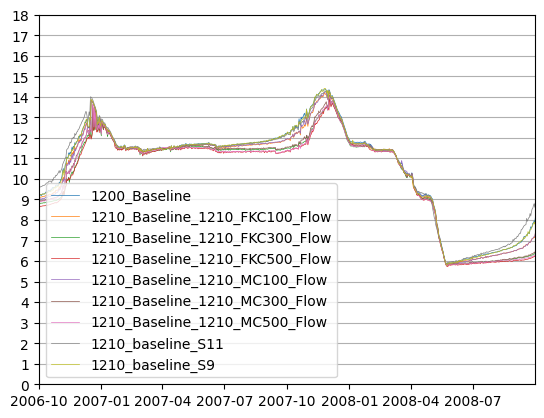

In [16]:
fig, ax = plt.subplots()
for run in mrr.runs:
    temp = run.two.get_structure(4)
    ax.plot(
        jday_to_date(temp["JDAY"]),
        temp["Temperature [C]"],
        label=run.name,
        linewidth=0.5,
    )
ax.set_ylim(0, 18)
ax.yaxis.set_major_locator(ticker.MultipleLocator(1))
ax.grid(axis="y")
ax.set_xlim(pd.Timestamp('2006-10-01'), pd.Timestamp('2008-09-30'))
ax.legend()
plt.show()
fig.savefig("release_temps.png", dpi=300, bbox_inches="tight")